# 03 — Machine learning
Objetivo: treinar classificadores (Logistic Regression como referência, **Random Forest** e **SVM**) para duas tarefas: `falha` (falha agora) e `falha_nas_proximas_24h` (antecipação). Segunda das 3 abordagens a comparar.

**Regras de ouro para não haver fuga de informação (data leakage):**
1. As features só usam o passado e o presente de cada máquina.
2. Nunca usamos `falha`, `tipo_falha`, `falha_nas_proximas_24h` nem `leitura_anomala_sensor` como features.
3. Validação **por máquina**: o modelo nunca é testado numa máquina que viu no treino.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, precision_recall_curve, f1_score, precision_score, recall_score
from src.dados import carregar_leituras
from src.features import construir_features, PROIBIDAS
from src.modelos import criar_modelo, proba_por_maquina, melhor_limiar
from src.regras import aplicar_regras

df = carregar_leituras()
d, FEATURES = construir_features(df)
assert not set(FEATURES) & set(PROIBIDAS)      # garantia anti-fuga
BASE = [c for c in FEATURES if not c.startswith(('vib_', 'pres_'))]
print(len(FEATURES), 'features;', len(FEATURES) - len(BASE), 'são temporais')
print(FEATURES)

25 features; 12 são temporais
['temp_ar_K', 'temp_processo_K', 'velocidade_rpm', 'binario_Nm', 'desgaste_ferramenta_min', 'vibracao_mm_s', 'pressao_bar', 'corrente_A', 'horas_desde_manutencao', 'delta_T', 'potencia_W', 'desgaste_x_binario', 'qualidade', 'vib_media5', 'vib_media20', 'vib_std5', 'vib_delta1', 'vib_tend10', 'vib_vs_media20', 'pres_media5', 'pres_media20', 'pres_std5', 'pres_delta1', 'pres_tend10', 'pres_vs_media20']


## 1. Treino e avaliação (validação por máquina, 4 grupos)
Cada leitura recebe uma probabilidade prevista por um modelo que **não viu aquela máquina**. Demora ~1 minuto.

In [2]:
ALVOS = ['falha', 'falha_nas_proximas_24h']
MODELOS = ['LogReg', 'RF', 'SVM']
prob, linhas = {}, []
for alvo in ALVOS:
    y = d[alvo]
    for m in MODELOS:
        p = proba_por_maquina(m, d[FEATURES], y, d.id_maquina)
        prob[(alvo, m)] = p
        b = melhor_limiar(y, p)
        linhas.append(dict(alvo=alvo, modelo=m, PR_AUC=average_precision_score(y, p),
                           F1_a_0_5=f1_score(y, p > 0.5), F1_melhor=b['F1'],
                           precisao=b['precisao'], recall=b['recall'], limiar=b['limiar']))
res = pd.DataFrame(linhas).round(3)
res

C:\Users\Admin\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Admin\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Admin\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
C:\Users\Admin\AppData\Local\Python\pythoncore-3.13-64\Lib\site-packages\sklearn\svm\

,alvo,modelo,PR_AUC,F1_a_0_5,F1_melhor,precisao,recall,limiar
0,falha,LogReg,0.176,0.156,0.282,0.285,0.279,0.860
1,falha,RF,0.400,0.281,0.420,0.346,0.536,0.279
2,falha,SVM,0.242,0.100,0.317,0.307,0.329,0.213
3,falha_nas_proximas_24h,LogReg,0.893,0.836,0.839,0.854,0.824,0.484
4,falha_nas_proximas_24h,RF,0.928,0.852,0.854,0.885,0.825,0.491
5,falha_nas_proximas_24h,SVM,0.886,0.845,0.846,0.891,0.806,0.583


## 2. Comparação com o sistema de regras
As regras não têm probabilidade, só alarme sim/não, por isso comparamos o F1 (e a precisão/recall) do conjunto das regras com o melhor modelo.

In [3]:
r = aplicar_regras(df)
for alvo in ALVOS:
    y = d[alvo]
    print(f'{alvo:24} REGRAS  P={precision_score(y, r.alarme):.2f} R={recall_score(y, r.alarme):.2f} F1={f1_score(y, r.alarme):.2f}')
    print(f'{"":24} RF      ', res[(res.alvo == alvo) & (res.modelo == "RF")][['precisao', 'recall', 'F1_melhor']].round(2).to_dict('records')[0])

falha                    REGRAS  P=0.23 R=0.94 F1=0.36
                         RF       {'precisao': 0.35, 'recall': 0.54, 'F1_melhor': 0.42}
falha_nas_proximas_24h   REGRAS  P=0.81 R=0.18 F1=0.30
                         RF       {'precisao': 0.88, 'recall': 0.82, 'F1_melhor': 0.85}


## 3. Curvas precisão–recall
Quanto mais perto do canto superior direito, melhor. O ponto preto são as regras.

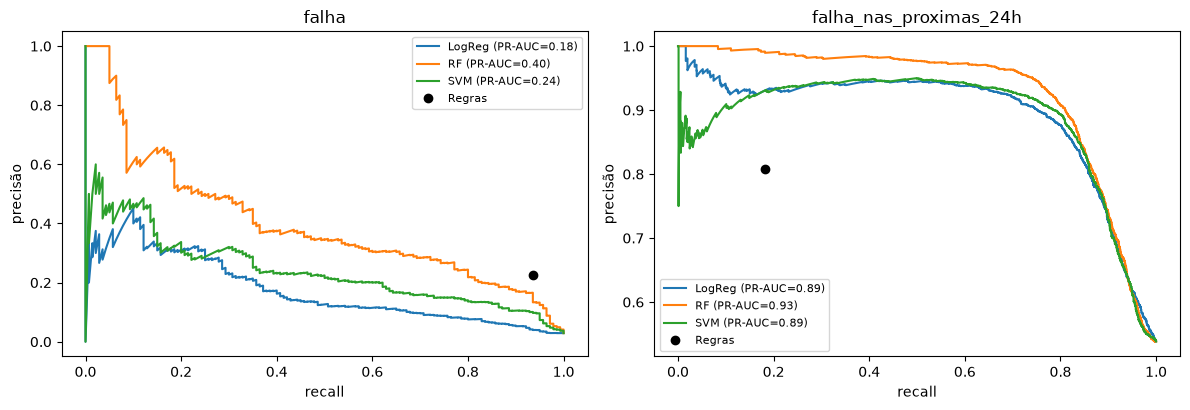

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, alvo in zip(ax, ALVOS):
    y = d[alvo]
    for m in MODELOS:
        pr, rc, _ = precision_recall_curve(y, prob[(alvo, m)])
        a.plot(rc, pr, label=f'{m} (PR-AUC={average_precision_score(y, prob[(alvo, m)]):.2f})')
    a.plot(recall_score(y, r.alarme), precision_score(y, r.alarme), 'ko', label='Regras')
    a.set_title(alvo); a.set_xlabel('recall'); a.set_ylabel('precisão'); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig('../figuras/curvas_pr.png', dpi=150); plt.show()

## 4. As features temporais ajudam? (ablação)
Comparamos o Random Forest **só com os sensores atuais** contra **sensores + features temporais**.

In [5]:
linhas = []
for alvo in ALVOS:
    y = d[alvo]
    for nome, fs in [('sem temporais', BASE), ('com temporais', FEATURES)]:
        p = proba_por_maquina('RF', d[fs], y, d.id_maquina)
        linhas.append(dict(alvo=alvo, features=nome, PR_AUC=average_precision_score(y, p), F1=melhor_limiar(y, p)['F1']))
pd.DataFrame(linhas).round(3)

,alvo,features,PR_AUC,F1
0,falha,sem temporais,0.364,0.441
1,falha,com temporais,0.400,0.420
2,falha_nas_proximas_24h,sem temporais,0.927,0.852
3,falha_nas_proximas_24h,com temporais,0.928,0.854


## 5. Que tipos de falha o ML apanha?
Usamos o RF para `falha` com o limiar que maximiza o F1 e vemos o recall por tipo (comparar com as regras no notebook 02).

In [6]:
y = d['falha']; p = prob[('falha', 'RF')]; lim = melhor_limiar(y, p)['limiar']
pred = pd.Series(p >= lim, index=d.index)
f = d[d.falha == 1]
tab = pd.DataFrame({'ML_apanhadas': pred[f.index].groupby(f.tipo_falha).sum(),
                    'Regras_apanhadas': r.alarme[f.index].groupby(f.tipo_falha).sum(),
                    'total': f.groupby('tipo_falha').size()})
tab

,ML_apanhadas,Regras_apanhadas,total
tipo_falha,,,
BRG,20,18,22
HDF,0,10,10
OSF,15,17,17
PWF,14,24,24
RNF,0,0,4
TWF,26,62,63


## 6. O que o Random Forest usa? (importância das features)

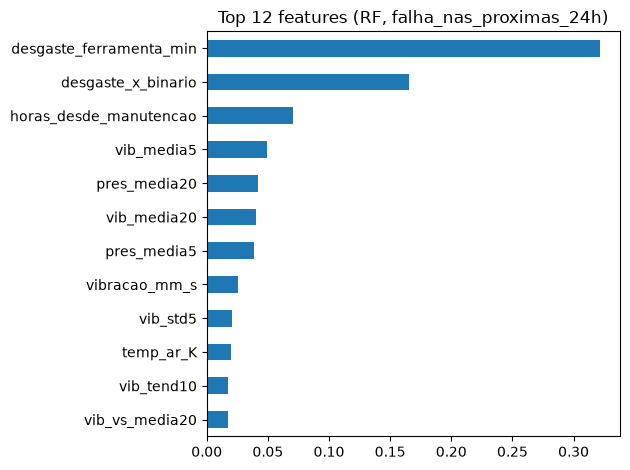

In [7]:
rf = criar_modelo('RF').fit(d[FEATURES], d['falha_nas_proximas_24h'])
imp = pd.Series(rf[-1].feature_importances_, index=FEATURES).sort_values().tail(12)
imp.plot.barh(title='Top 12 features (RF, falha_nas_proximas_24h)'); plt.tight_layout()
plt.savefig('../figuras/importancia_features.png', dpi=150); plt.show()

## 7. Guardar as previsões para o Passo 4 (híbrido)

In [9]:
out = d[['id_leitura', 'id_maquina', 'ciclo', 'falha', 'tipo_falha', 'falha_nas_proximas_24h']].copy()
for (alvo, m), p in prob.items():
    out[f'p_{m}_{alvo}'] = p
out.to_csv('../resultados/previsoes_ml.csv', index=False)
print('Guardado em resultados/previsoes_ml.csv:', out.shape)

Guardado em resultados/previsoes_ml.csv: (4800, 12)


## Conclusões do Passo 3 

O Random Forest foi o modelo com melhores resultados, superando a Regressão Logística e o SVM. Na previsão de falha_nas_proximas_24h obteve PR-AUC ≈ 0,93 e F1 ≈ 0,85, enquanto na deteção da falha no momento atingiu PR-AUC ≈ 0,40 e F1 ≈ 0,42.

Comparando com as regras, o ganho é especialmente visível na antecipação de falhas. As regras têm um F1 de 0,30 e um recall de apenas 18%, enquanto o Random Forest alcança 82% de recall e 88% de precisão. Já na deteção da falha atual, o modelo apresenta melhor precisão (0,35 vs. 0,23) e melhor F1 (0,42 vs. 0,36), mas as regras continuam a ter um recall muito superior (94% vs. 54%).

A antecipação a 24 horas é mais fácil porque depende da degradação gradual da máquina, visível nos sensores. Pelo contrário, a falha exata também depende de fatores aleatórios, como acontece nas falhas PWF, OSF, HDF e, sobretudo, nas RNF, o que limita naturalmente o desempenho dos modelos.

Por tipo de falha, o modelo identifica bem as BRG (20 em 22) e as OSF (15 em 17), mas não consegue detetar nenhuma HDF ou RNF, e encontra apenas 26 das 63 falhas TWF. As regras, por sua vez, têm melhor desempenho nas HDF, PWF, OSF e TWF, mostrando que as duas abordagens se complementam.

As variáveis mais importantes para o modelo foram desgaste_ferramenta_min (0,32), desgaste_x_binario (0,17) e horas_desde_manutencao (0,07). As features temporais de vibração e pressão também contribuíram, mas com impacto relativamente reduzido.

Como limitações, o limiar de decisão foi ajustado usando os mesmos dados da avaliação, o que pode tornar os resultados ligeiramente otimistas. Além disso, os dados são sintéticos e existem apenas 140 falhas, pelo que alguns resultados, especialmente para tipos raros como a RNF, têm baixa fiabilidade estatística.

No geral, como as regras e o machine learning detetam falhas diferentes, o passo seguinte é combinar ambas as abordagens num sistema híbrido, aproveitando a capacidade preditiva do ML e a interpretabilidade das regras.